# 01. 특징 검증 (EDA)

추출된 `data/features.csv`를 로딩하고 모델링 전 품질을 확인한다.  
**선행 조건:** `python src/build_dataset.py` 실행 완료

In [1]:
import sys, warnings
warnings.filterwarnings('ignore')
sys.path.append('../src')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from features import FEATURE_NAMES

plt.rcParams['figure.dpi'] = 100

CLASSES  = ['ordinario', 'pizzicato_secco', 'tremolo', 'sul_ponticello', 'col_legno_battuto']
CSV_PATH = Path('../data/features.csv')

assert CSV_PATH.exists(), f'먼저 build_dataset.py를 실행하세요'
df = pd.read_csv(CSV_PATH)
print(f'shape: {df.shape}')

shape: (1000, 249)


In [2]:
# 1. NaN / Inf 점검
nan_count = df[FEATURE_NAMES].isna().sum().sum()
inf_count = np.isinf(df[FEATURE_NAMES].values).sum()
print(f'NaN: {nan_count},  Inf: {inf_count}')
print('→ 모두 0이면 모델링 진행 가능')

NaN: 0,  Inf: 0
→ 모두 0이면 모델링 진행 가능


In [3]:
# 2. 클래스별 샘플 수
print(df.groupby('label')['label'].count().reindex(CLASSES).to_string())

label
ordinario            200
pizzicato_secco      200
tremolo              200
sul_ponticello       200
col_legno_battuto    200


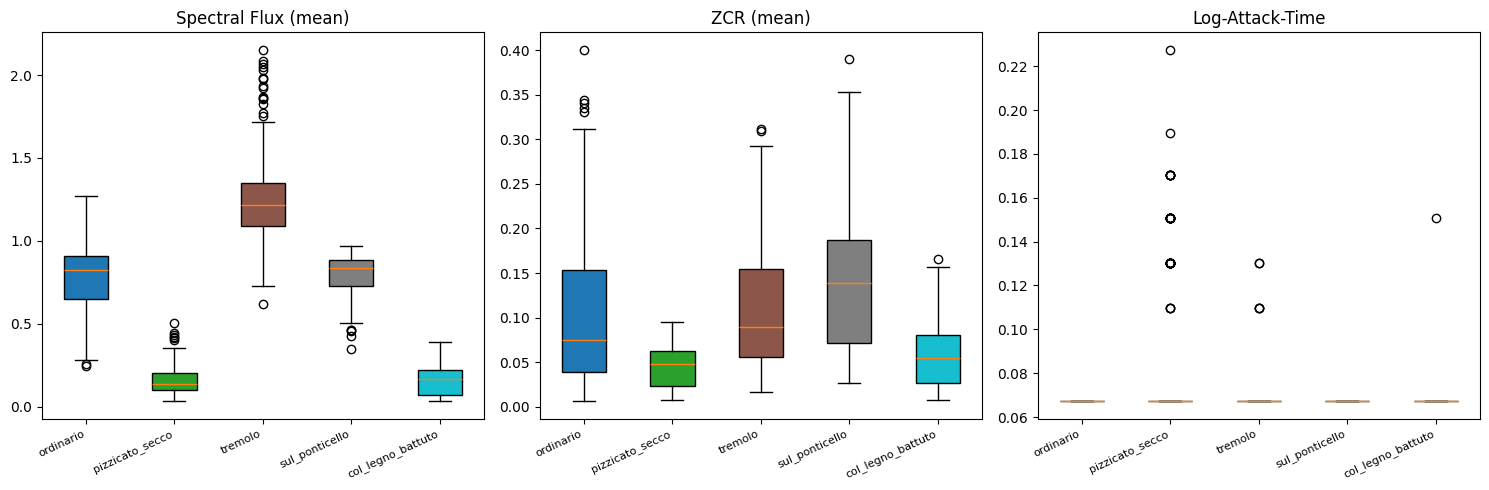

In [4]:
# 3. 핵심 특징 3종 — 클래스별 boxplot
# 기대 패턴:
#   log_attack_time  → pizzicato_secco, col_legno_battuto 가 낮아야 함 (빠른 어택)
#   zcr              → col_legno_battuto 가 높아야 함 (잡음성)
#   flux             → pizzicato_secco, col_legno_battuto 가 높아야 함 (강한 onset)
plot_feats  = ['flux_mean_0', 'zcr_mean_0', 'log_attack_time']
plot_titles = ['Spectral Flux (mean)', 'ZCR (mean)', 'Log-Attack-Time']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors = plt.cm.tab10(np.linspace(0, 1, len(CLASSES)))

for ax, feat, title in zip(axes, plot_feats, plot_titles):
    data = [df[df['label'] == cls][feat].values for cls in CLASSES]
    bp   = ax.boxplot(data, labels=CLASSES, patch_artist=True)
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
    ax.set_title(title)
    ax.set_xticklabels(CLASSES, rotation=25, ha='right', fontsize=8)

plt.tight_layout()
plt.show()

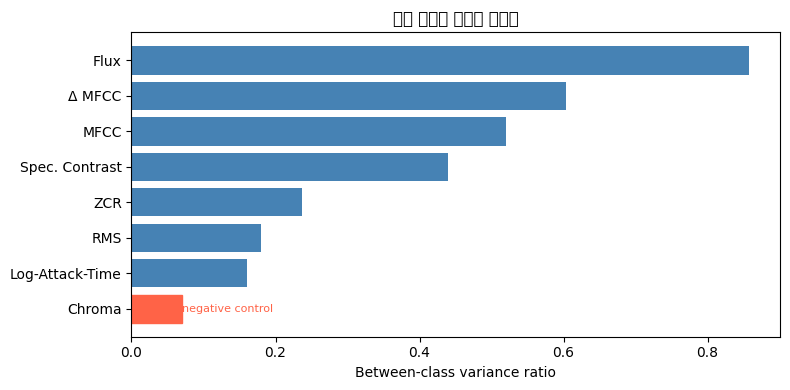

Flux               0.8576
Δ MFCC             0.6035
MFCC               0.5195
Spec. Contrast     0.4389
ZCR                0.2372
RMS                0.1797
Log-Attack-Time    0.1610
Chroma             0.0695


In [5]:
# 4. 특징 그룹별 클래스 변별력
# Chroma 가 제일 낮게 나오면 정상 (음성 대조군)
groups = {
    'MFCC':            [c for c in FEATURE_NAMES if c.startswith('mfcc_mean')],
    'Δ MFCC':          [c for c in FEATURE_NAMES if c.startswith('mfcc_d_mean')],
    'Spec. Contrast':  [c for c in FEATURE_NAMES if c.startswith('sc_mean')],
    'Flux':            [c for c in FEATURE_NAMES if c.startswith('flux_mean')],
    'ZCR':             [c for c in FEATURE_NAMES if c.startswith('zcr_mean')],
    'RMS':             [c for c in FEATURE_NAMES if c.startswith('rms_mean')],
    'Chroma':          [c for c in FEATURE_NAMES if c.startswith('chroma_mean')],
    'Log-Attack-Time': ['log_attack_time'],
}

scores = {}
for name, cols in groups.items():
    X_g         = df[cols].values
    total_var   = X_g.var(axis=0).mean()
    class_means = np.array([df[df['label'] == cls][cols].mean().values for cls in CLASSES])
    scores[name] = class_means.var(axis=0).mean() / (total_var + 1e-10)

score_s = pd.Series(scores).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(score_s.index, score_s.values, color='steelblue')
for bar, name in zip(bars, score_s.index):
    if name == 'Chroma':
        bar.set_color('tomato')
        ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height() / 2,
                'negative control', va='center', fontsize=8, color='tomato')
ax.set_xlabel('Between-class variance ratio')
ax.set_title('특징 그룹별 클래스 변별력')
plt.tight_layout()
plt.show()

print(score_s.sort_values(ascending=False).round(4).to_string())